# EN3160 Assignment 3: Neural Networks

**Name:** [Name needed]  
**Index number:** 230070T  
**GitHub profile:** [Profile link needed]

In [1]:
import os
os.environ["TORCH_HOME"] = "./data/torch"
import random
import time
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms, models
from IPython.display import display, Markdown

SEED = 42
def set_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
torch.set_num_threads(4)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
Path("results").mkdir(exist_ok=True)
print("Device:", device)
print("PyTorch:", torch.__version__)
print("Seed:", SEED)

def make_loader(dataset, batch_size, shuffle=False):
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                      num_workers=0, generator=generator)

def save_figure(name):
    plt.tight_layout()
    plt.savefig("results/" + name + ".png", dpi=150, bbox_inches="tight")
    plt.show()

def plot_history(history, title, name, evaluation="Test"):
    epochs = range(1, len(history) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for ax, metric in zip(axes, ["loss", "acc"]):
        ax.plot(epochs, [h["train_" + metric] for h in history], "o-", label="Train")
        ax.plot(epochs, [h["test_" + metric] for h in history], "o-", label=evaluation)
        ax.set(xlabel="Epoch", ylabel="Loss" if metric == "loss" else "Accuracy (%)")
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    save_figure(name)

def print_history(history):
    print("Epoch  Train loss  Eval loss  Train acc  Eval acc")
    for i, h in enumerate(history, 1):
        print(f"{i:5d}  {h['train_loss']:10.4f}  {h['test_loss']:9.4f}"
              f"  {h['train_acc']:9.2f}  {h['test_acc']:8.2f}")

Device: cpu
PyTorch: 2.14.1+cpu
Seed: 42


## 1. CIFAR-10 with manual backpropagation
The network is 3072 -> 100 sigmoid units -> 10 output logits. Softmax turns the logits
into class probabilities. Cross-entropy is calculated with log-softmax for numerical stability.
For a batch of N images, the output gradient is `(probabilities - one_hot_labels) / N`.
The hidden-layer gradient includes the sigmoid derivative `h * (1 - h)`.

The batch size is 50, as in the supplied listing. The learning rate starts at 0.1 and
is multiplied by 0.9 after each epoch. Xavier-style initialization replaces the very small
initialization in the listing; the learning rate is also adjusted for mean cross-entropy.
No optimizer or automatic differentiation is used to train this network.

In [2]:
cifar_train = datasets.CIFAR10("data", train=True, download=True)
cifar_test = datasets.CIFAR10("data", train=False, download=True)

def cifar_tensors(dataset):
    x = torch.tensor(dataset.data).permute(0, 3, 1, 2).float() / 255
    x = ((x - 0.5) / 0.5).reshape(-1, 3072)
    return TensorDataset(x, torch.tensor(dataset.targets))

cifar_train_data = cifar_tensors(cifar_train)
cifar_test_data = cifar_tensors(cifar_test)
cifar_train_loader = make_loader(cifar_train_data, 50, True)
cifar_train_eval = make_loader(cifar_train_data, 256)
cifar_test_loader = make_loader(cifar_test_data, 256)
print("CIFAR-10 train/test:", len(cifar_train_data), len(cifar_test_data))

set_seed()
W1 = torch.randn(3072, 100, device=device) * np.sqrt(2 / (3072 + 100))
b1 = torch.zeros(100, device=device)
W2 = torch.randn(100, 10, device=device) * np.sqrt(2 / (100 + 10))
b2 = torch.zeros(10, device=device)

def dense_forward(x):
    hidden = torch.sigmoid(x @ W1 + b1)
    return hidden, hidden @ W2 + b2

@torch.no_grad()
def evaluate_dense(loader):
    loss_sum, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        _, logits = dense_forward(x)
        loss_sum += nn.functional.cross_entropy(logits, y, reduction="sum").item()
        correct += (logits.argmax(1) == y).sum().item()
        total += len(y)
    return loss_sum / total, 100 * correct / total

CIFAR-10 train/test: 50000 10000


Epoch 1: train 41.67%, test 41.50%


Epoch 2: train 44.43%, test 42.59%


Epoch 3: train 46.45%, test 44.02%


Epoch 4: train 47.79%, test 45.23%


Epoch 5: train 49.63%, test 46.03%


...

Epoch 7: train 50.75%, test 46.47%


Epoch 8: train 52.35%, test 47.49%


Epoch 9: train 52.93%, test 47.66%


Epoch 10: train 53.71%, test 47.80%


Epoch  Train loss  Eval loss  Train acc  Eval acc
    1      1.6871     1.7048      41.67     41.50
    2      1.6186     1.6522      44.43     42.59
    3      1.5635     1.6174      46.45     44.02
    4      1.5169     1.5845      47.79     45.23
    5      1.4784     1.5644      49.63     46.03
    6      1.4452     1.5421      50.66     46.56
    7      1.4326     1.5452      50.75     46.47
    8      1.3946     1.5192      52.35     47.49
    9      1.3782     1.5189      52.93     47.66
   10      1.3561     1.5083      53.71     47.80


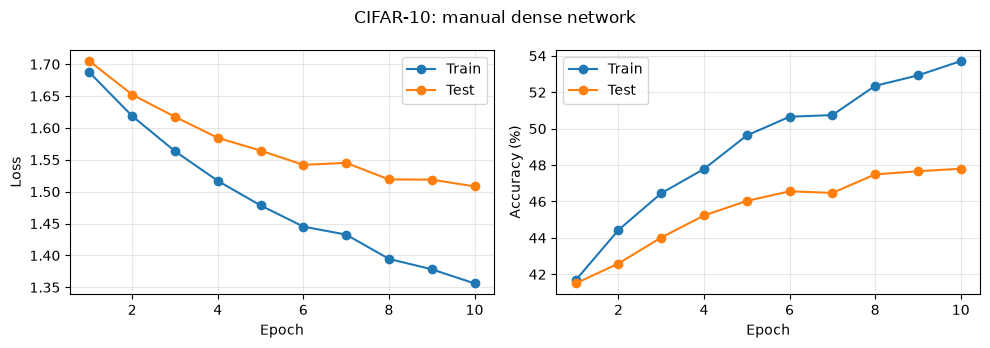

In [3]:
dense_history = []
learning_rate = 0.1
start = time.perf_counter()
for epoch in range(10):
    for x, y in cifar_train_loader:
        x, y = x.to(device), y.to(device)
        hidden, logits = dense_forward(x)
        log_prob = torch.log_softmax(logits, dim=1)
        loss = -log_prob[torch.arange(len(y), device=device), y].mean()
        targets = nn.functional.one_hot(y, 10).float()

        dz2 = (log_prob.exp() - targets) / len(y)
        dW2 = hidden.T @ dz2
        db2 = dz2.sum(0)
        dz1 = (dz2 @ W2.T) * hidden * (1 - hidden)
        dW1 = x.T @ dz1
        db1 = dz1.sum(0)

        W1 -= learning_rate * dW1
        b1 -= learning_rate * db1
        W2 -= learning_rate * dW2
        b2 -= learning_rate * db2

    train_loss, train_acc = evaluate_dense(cifar_train_eval)
    test_loss, test_acc = evaluate_dense(cifar_test_loader)
    dense_history.append(dict(train_loss=train_loss, train_acc=train_acc,
                              test_loss=test_loss, test_acc=test_acc))
    print(f"Epoch {epoch + 1}: train {train_acc:.2f}%, test {test_acc:.2f}%", flush=True)
    learning_rate *= 0.9
dense_seconds = time.perf_counter() - start
print_history(dense_history)
plot_history(dense_history, "CIFAR-10: manual dense network", "cifar_curves")

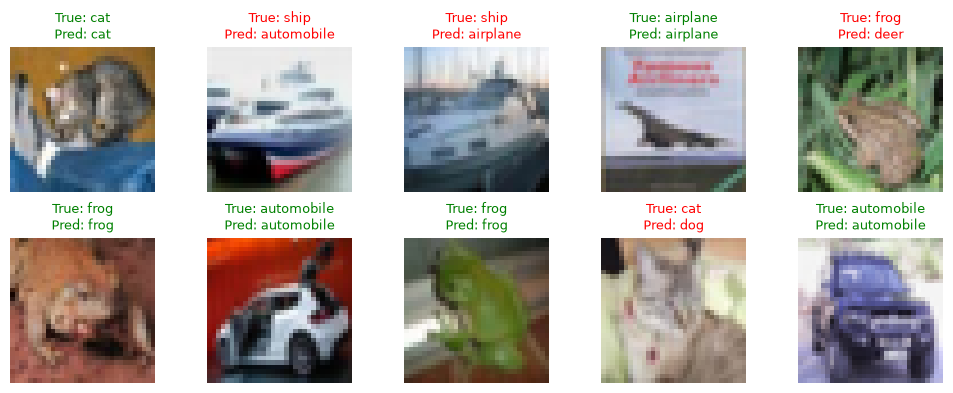

### Discussion
After 10 epochs, training accuracy is **53.71%** and test accuracy is
**47.80%**. The gap is **5.91 percentage points**.
Test loss changes from 1.7048 in epoch 1 to 1.5083
in epoch 10. Training accuracy indicates how well the model fits the training set;
test accuracy measures performance on unseen images. The gap indicates some overfitting
if training accuracy is higher. Flattening removes the explicit spatial organization of
the image, and 100 sigmoid units have limited capacity for varied natural images.
The example predictions show individual successes and mistakes; they are the first ten
test images, not a selection of only correct predictions.

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
with torch.no_grad():
    _, logits = dense_forward(cifar_test_data.tensors[0][:10].to(device))
predictions = logits.argmax(1).cpu().tolist()
for i, ax in enumerate(axes.flat):
    true_label = cifar_test.targets[i]
    ax.imshow(cifar_test.data[i])
    ax.set_title(f"True: {cifar_test.classes[true_label]}\nPred: {cifar_test.classes[predictions[i]]}",
                 fontsize=9, color="green" if predictions[i] == true_label else "red")
    ax.axis("off")
save_figure("cifar_predictions")
h = dense_history[-1]
display(Markdown(f"""### Discussion
After 10 epochs, training accuracy is **{h['train_acc']:.2f}%** and test accuracy is
**{h['test_acc']:.2f}%**. The gap is **{h['train_acc'] - h['test_acc']:.2f} percentage points**.
Test loss changes from {dense_history[0]['test_loss']:.4f} in epoch 1 to {h['test_loss']:.4f}
in epoch 10. Training accuracy indicates how well the model fits the training set;
test accuracy measures performance on unseen images. The gap indicates some overfitting
if training accuracy is higher. Flattening removes the explicit spatial organization of
the image, and 100 sigmoid units have limited capacity for varied natural images.
The example predictions show individual successes and mistakes; they are the first ten
test images, not a selection of only correct predictions."""))

## 2. MNIST: LeNet-5 and a small modern CNN
Both models use the same 60,000 training images and 10,000 test images, normalization,
batch size 128, Adam optimizer (learning rate 0.001), cross-entropy loss and 10 epochs.
The seed and shuffled batch sequence are reset for each model. No data augmentation is used.
The test set is monitored as requested, but is not used for tuning or checkpoint selection.

LeNet-5 uses 6 and 16 convolutional channels, tanh activations, average pooling and
fully connected layers of 120, 84 and 10 units. Padding the first convolution allows
28x28 MNIST images. This is the usual fully connected PyTorch adaptation: the original
LeNet-5's sparse connections and RBF output are replaced by dense connections and logits.
The modern model uses three convolutions (16, 32 and 64 channels), batch normalization,
ReLU activations, max pooling and dropout before the final classifier.

In [5]:
mnist_train = datasets.MNIST("data", train=True, download=True)
mnist_test = datasets.MNIST("data", train=False, download=True)
def mnist_tensors(dataset):
    x = dataset.data.unsqueeze(1).float() / 255
    return TensorDataset((x - 0.1307) / 0.3081, dataset.targets)
mnist_train_data = mnist_tensors(mnist_train)
mnist_test_data = mnist_tensors(mnist_test)
mnist_train_eval = make_loader(mnist_train_data, 256)
mnist_test_loader = make_loader(mnist_test_data, 256)
print("MNIST train/test:", len(mnist_train_data), len(mnist_test_data))

class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(1, 6, 5, padding=2), nn.Tanh(), nn.AvgPool2d(2),
            nn.Conv2d(6, 16, 5), nn.Tanh(), nn.AvgPool2d(2),
            nn.Flatten(), nn.Linear(16 * 5 * 5, 120), nn.Tanh(),
            nn.Linear(120, 84), nn.Tanh(), nn.Linear(84, 10))
    def forward(self, x):
        return self.layers(x)

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16),
            nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32),
            nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64),
            nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Dropout(0.5), nn.Linear(64 * 3 * 3, 10))
    def forward(self, x):
        return self.layers(x)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    labels, predictions = [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss_sum += nn.functional.cross_entropy(logits, y, reduction="sum").item()
        pred = logits.argmax(1)
        correct += (pred == y).sum().item()
        total += len(y)
        labels.extend(y.cpu().tolist())
        predictions.extend(pred.cpu().tolist())
    return loss_sum / total, 100 * correct / total, np.array(labels), np.array(predictions)

def train_model(model, train_loader, train_eval, test_loader, optimizer,
                epochs=10, scheduler=None, frozen_backbone=False):
    history = []
    start = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        if frozen_backbone:
            model.eval()  # Freeze batch-normalization statistics as well as weights.
            model.fc.train()
        loss_sum = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            logits = model(x)
            loss = nn.functional.cross_entropy(logits, y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(y)
        train_loss, train_acc, _, _ = evaluate(model, train_eval)
        test_loss, test_acc, _, _ = evaluate(model, test_loader)
        history.append(dict(train_loss=train_loss, train_acc=train_acc,
                            test_loss=test_loss, test_acc=test_acc,
                            online_loss=loss_sum / len(train_loader.dataset)))
        print(f"Epoch {epoch + 1}: train {train_acc:.2f}%, eval {test_acc:.2f}%", flush=True)
        if scheduler is not None:
            scheduler.step()
    return history, time.perf_counter() - start

def confusion_plot(labels, predictions, names, title, filename):
    matrix = np.zeros((len(names), len(names)), dtype=int)
    np.add.at(matrix, (labels, predictions), 1)
    fig, ax = plt.subplots(figsize=(6, 5))
    image = ax.imshow(matrix, cmap="Blues")
    fig.colorbar(image, ax=ax)
    for i in range(len(names)):
        for j in range(len(names)):
            ax.text(j, i, str(matrix[i, j]), ha="center", va="center", fontsize=8,
                    color="white" if matrix[i, j] > matrix.max() / 2 else "black")
    ax.set(xticks=range(len(names)), yticks=range(len(names)),
           xticklabels=names, yticklabels=names, xlabel="Predicted class",
           ylabel="True class", title=title)
    save_figure(filename)
    return matrix

MNIST train/test: 60000 10000



LeNet-5


Epoch 1: train 96.72%, eval 96.76%


Epoch 2: train 98.11%, eval 97.90%


Epoch 3: train 98.62%, eval 98.28%


Epoch 4: train 98.73%, eval 98.37%


...

Epoch 7: train 99.23%, eval 98.75%


Epoch 8: train 99.51%, eval 98.89%


Epoch 9: train 99.50%, eval 98.80%


Epoch 10: train 99.72%, eval 98.95%


Epoch  Train loss  Eval loss  Train acc  Eval acc
    1      0.1120     0.1065      96.72     96.76
    2      0.0623     0.0651      98.11     97.90
    3      0.0440     0.0527      98.62     98.28
    4      0.0416     0.0531      98.73     98.37
    5      0.0246     0.0389      99.29     98.75
    6      0.0259     0.0432      99.18     98.77
    7      0.0239     0.0418      99.23     98.75
    8      0.0162     0.0382      99.51     98.89
    9      0.0154     0.0397      99.50     98.80
   10      0.0102     0.0324      99.72     98.95


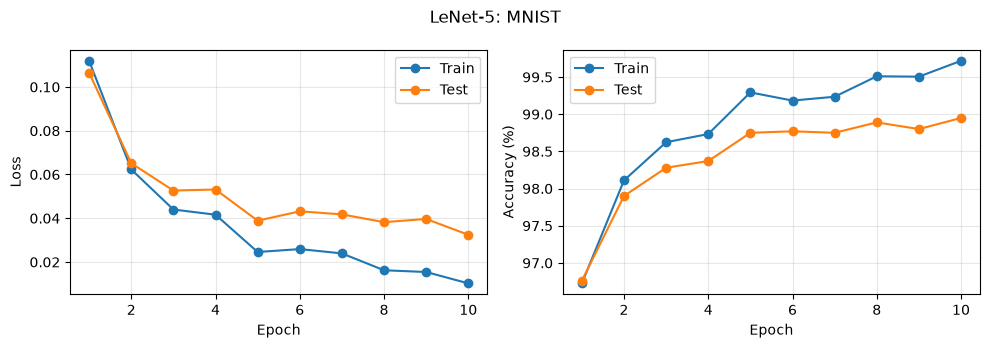

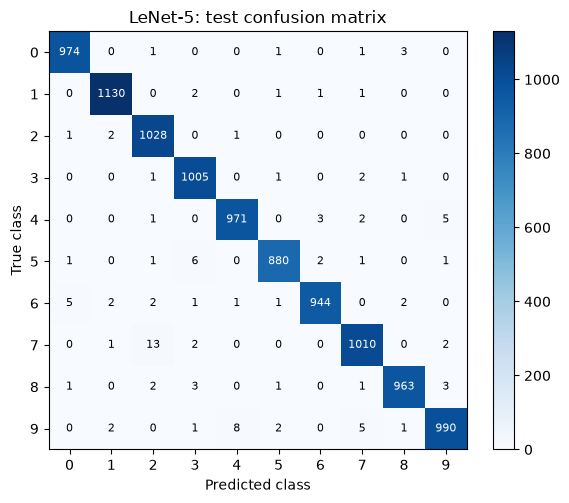


Small CNN


Epoch 1: train 98.33%, eval 98.48%


Epoch 2: train 98.65%, eval 98.67%


Epoch 3: train 99.22%, eval 99.08%


Epoch 4: train 99.31%, eval 99.09%


...

Epoch 7: train 99.52%, eval 99.21%


Epoch 8: train 99.58%, eval 99.17%


Epoch 9: train 99.56%, eval 99.15%


Epoch 10: train 99.68%, eval 99.22%


Epoch  Train loss  Eval loss  Train acc  Eval acc
    1      0.0547     0.0514      98.33     98.48
    2      0.0426     0.0416      98.65     98.67
    3      0.0267     0.0288      99.22     99.08
    4      0.0227     0.0282      99.31     99.09
    5      0.0258     0.0343      99.20     98.92
    6      0.0221     0.0320      99.33     99.01
    7      0.0162     0.0238      99.52     99.21
    8      0.0144     0.0248      99.58     99.17
    9      0.0148     0.0263      99.56     99.15
   10      0.0110     0.0254      99.68     99.22


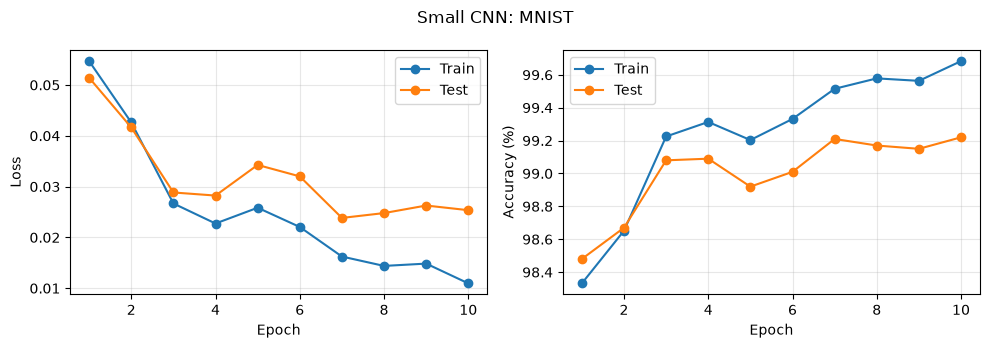

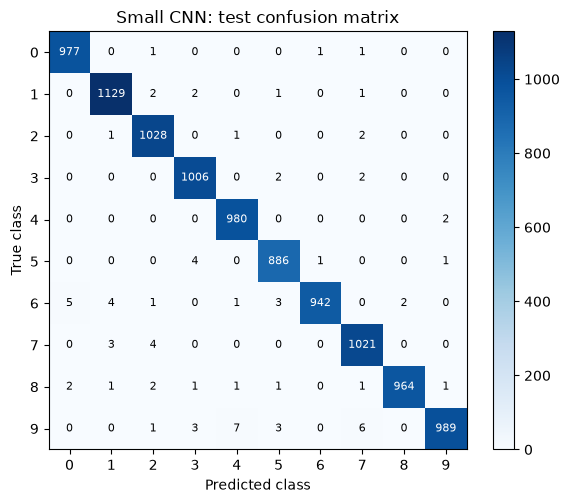

In [6]:
mnist_results = {}
mnist_models = {}
for name, model_class in [("LeNet-5", LeNet5), ("Small CNN", SmallCNN)]:
    set_seed()
    model = model_class().to(device)
    train_loader = make_loader(mnist_train_data, 128, True)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    print("\n" + name, flush=True)
    history, seconds = train_model(model, train_loader, mnist_train_eval,
                                    mnist_test_loader, optimizer)
    _, _, labels, predictions = evaluate(model, mnist_test_loader)
    mnist_results[name] = dict(history=history, seconds=seconds,
                              parameters=sum(p.numel() for p in model.parameters()))
    mnist_models[name] = model
    print_history(history)
    plot_history(history, name + ": MNIST", name.replace(" ", "_") + "_curves")
    matrix = confusion_plot(labels, predictions, list(range(10)),
                            name + ": test confusion matrix", name.replace(" ", "_") + "_confusion")
    mnist_results[name]["confusion"] = matrix.tolist()

Model       Parameters  Train acc  Test acc  Test loss  Time (s)
LeNet-5          61706      99.72     98.95     0.0324      50.7
Small CNN        29290      99.68     99.22     0.0254     151.6


### Comparison and discussion
LeNet-5 achieves **98.95%** test accuracy and the small CNN achieves
**99.22%**. The CNN minus LeNet-5 difference is **0.27
percentage points**. Their training-minus-test gaps are 0.77
and 0.46 points, respectively. A smaller gap is useful,
but should be considered together with the absolute test accuracy and loss.

Both models use spatial filters and shared weights, which suit handwritten digits.
The modern CNN combines batch normalization, ReLU and dropout. This comparison tests
the complete architectures; it cannot isolate the contribution of any one component.
Cross-entropy also depends on confidence, so it can worsen even when accuracy improves
if the remaining mistakes become more confident. These are single-seed results, not
evidence that a small accuracy difference will hold across repeated runs.

For **LeNet-5**, the most frequent directed confusion is true digit **7** predicted as **2**, with **13** images. The off-diagonal entries count mistakes; the diagonal counts correct predictions.

For **Small CNN**, the most frequent directed confusion is true digit **9** predicted as **4**, with **7** images. The off-diagonal entries count mistakes; the diagonal counts correct predictions.

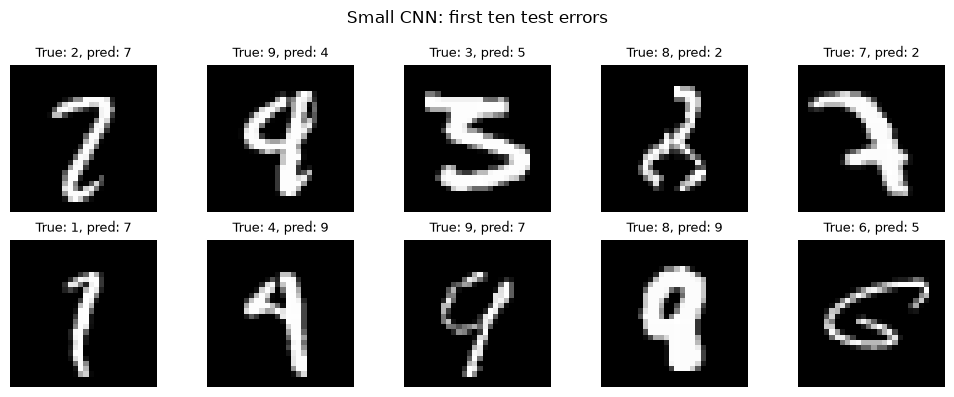

In [7]:
print("Model       Parameters  Train acc  Test acc  Test loss  Time (s)")
for name, result in mnist_results.items():
    h = result["history"][-1]
    print(f"{name:11s} {result['parameters']:10d} {h['train_acc']:10.2f}"
          f" {h['test_acc']:9.2f} {h['test_loss']:10.4f} {result['seconds']:9.1f}")

a = mnist_results["LeNet-5"]["history"][-1]
b = mnist_results["Small CNN"]["history"][-1]
display(Markdown(f"""### Comparison and discussion
LeNet-5 achieves **{a['test_acc']:.2f}%** test accuracy and the small CNN achieves
**{b['test_acc']:.2f}%**. The CNN minus LeNet-5 difference is **{b['test_acc'] - a['test_acc']:.2f}
percentage points**. Their training-minus-test gaps are {a['train_acc'] - a['test_acc']:.2f}
and {b['train_acc'] - b['test_acc']:.2f} points, respectively. A smaller gap is useful,
but should be considered together with the absolute test accuracy and loss.

Both models use spatial filters and shared weights, which suit handwritten digits.
The modern CNN combines batch normalization, ReLU and dropout. This comparison tests
the complete architectures; it cannot isolate the contribution of any one component.
Cross-entropy also depends on confidence, so it can worsen even when accuracy improves
if the remaining mistakes become more confident. These are single-seed results, not
evidence that a small accuracy difference will hold across repeated runs."""))

for name, result in mnist_results.items():
    matrix = np.array(result["confusion"])
    off_diagonal = matrix.copy()
    np.fill_diagonal(off_diagonal, 0)
    true, pred = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)
    display(Markdown(f"For **{name}**, the most frequent directed confusion is true digit "
                     f"**{true}** predicted as **{pred}**, with **{matrix[true, pred]}** images. "
                     "The off-diagonal entries count mistakes; the diagonal counts correct predictions."))

model = mnist_models["Small CNN"]
_, _, labels, predictions = evaluate(model, mnist_test_loader)
wrong = np.flatnonzero(labels != predictions)[:10]
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, wrong):
    ax.imshow(mnist_test.data[i], cmap="gray")
    ax.set_title(f"True: {labels[i]}, pred: {predictions[i]}", fontsize=9)
fig.suptitle("Small CNN: first ten test errors")
save_figure("mnist_errors")

### Reading the MNIST results
The small CNN has fewer parameters but takes longer in this run. Parameter count
measures stored weights, while computation also depends on the number of spatial
positions processed by each convolution; batch normalization adds work too.
The displayed errors include 4/9 and 3/5 confusions with overlapping stroke patterns.
These examples help explain some mistakes, but do not explain every test error.


## 3. Transfer learning with ResNet18
The ImageNet-1K pretrained ResNet18 is adapted to ants and bees using the hymenoptera
dataset from the PyTorch tutorial. Both methods use the same initial classifier,
10 epochs, batch size 16, SGD with learning rate 0.001 and momentum 0.9, and a StepLR
schedule (multiply the rate by 0.1 after 7 epochs).

Fine-tuning updates every layer. Feature extraction updates only the new two-class
linear layer; the backbone and its batch-normalization statistics remain fixed.
Training uses random resized crops to 224x224 and horizontal flips. Evaluation uses
resize to 256 followed by a 224x224 center crop. Both use ImageNet normalization.
The supplied `val` split is a validation set, not an independent test set. Results below
use the final epoch for both methods, with no best-epoch selection.

Classes: ['ants', 'bees']
Training / validation images: 244 153
train {'ants': 123, 'bees': 121}
val {'ants': 70, 'bees': 83}



Fine-tuning


Epoch 1: train 90.57%, eval 90.20%


Epoch 2: train 95.49%, eval 94.12%


Epoch 3: train 97.95%, eval 94.77%


...

Epoch 7: train 99.59%, eval 93.46%


Epoch 8: train 100.00%, eval 92.16%


Epoch 9: train 100.00%, eval 92.81%


Epoch 10: train 100.00%, eval 92.81%


Epoch  Train loss  Eval loss  Train acc  Eval acc
    1      0.2832     0.3134      90.57     90.20
    2      0.1320     0.1929      95.49     94.12
    3      0.0936     0.1739      97.95     94.77
    4      0.0739     0.1781      98.36     94.12
    5      0.0584     0.1733      98.77     94.12
    6      0.0401     0.1663      99.18     93.46
    7      0.0290     0.1715      99.59     93.46
    8      0.0294     0.1848     100.00     92.16
    9      0.0282     0.1745     100.00     92.81
   10      0.0266     0.1720     100.00     92.81


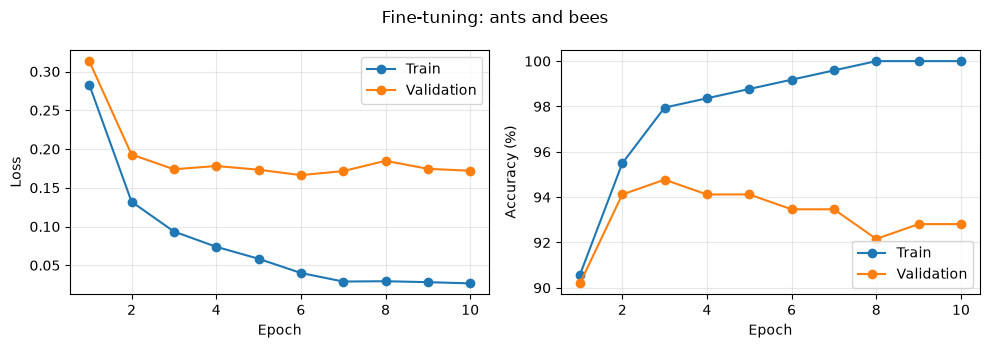

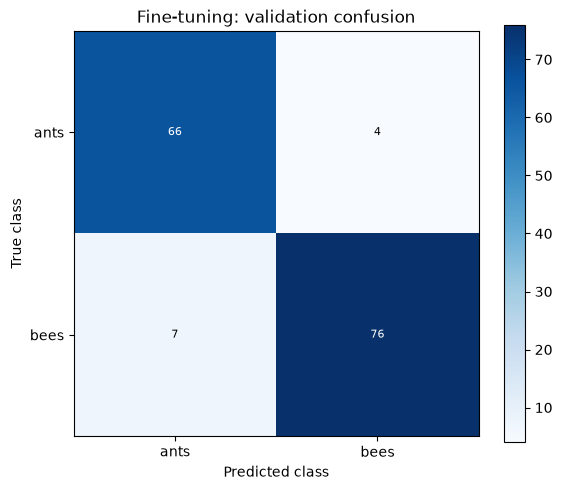


Feature extraction


Epoch 1: train 95.08%, eval 95.42%


Epoch 2: train 95.90%, eval 95.42%


Epoch 3: train 97.95%, eval 94.77%


Epoch 4: train 97.54%, eval 95.42%


...

Epoch 7: train 97.13%, eval 96.08%


Epoch 8: train 97.54%, eval 96.08%


Epoch 9: train 97.54%, eval 96.08%


Epoch 10: train 97.54%, eval 96.08%


Epoch  Train loss  Eval loss  Train acc  Eval acc
    1      0.2399     0.2459      95.08     95.42
    2      0.1457     0.1584      95.90     95.42
    3      0.1017     0.1421      97.95     94.77
    4      0.0926     0.1283      97.54     95.42
    5      0.0817     0.1261      97.54     96.08
    6      0.0837     0.1463      97.54     94.77
    7      0.0749     0.1201      97.13     96.08
    8      0.0712     0.1209      97.54     96.08
    9      0.0704     0.1215      97.54     96.08
   10      0.0692     0.1230      97.54     96.08


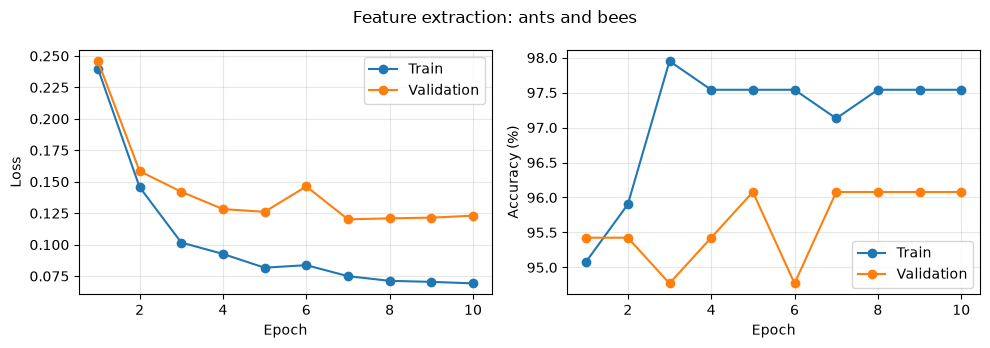

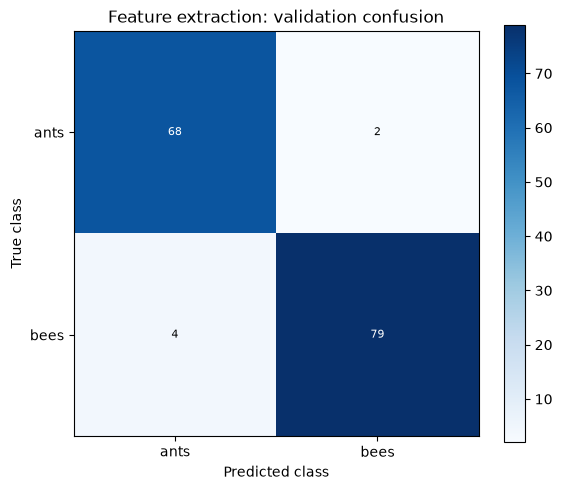

In [8]:
from torchvision.datasets.utils import download_and_extract_archive

data_dir = Path("data/hymenoptera_data")
if not data_dir.exists():
    download_and_extract_archive(
        "https://download.pytorch.org/tutorial/hymenoptera_data.zip", "data")
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224), transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), transforms.Normalize(mean, std)])
eval_transform = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(224),
    transforms.ToTensor(), transforms.Normalize(mean, std)])
insect_train = datasets.ImageFolder(data_dir / "train", train_transform)
insect_train_eval = datasets.ImageFolder(data_dir / "train", eval_transform)
insect_val = datasets.ImageFolder(data_dir / "val", eval_transform)
insect_train_eval_loader = make_loader(insect_train_eval, 16)
insect_val_loader = make_loader(insect_val, 16)
print("Classes:", insect_train.classes)
print("Training / validation images:", len(insect_train), len(insect_val))
for split, dataset in [("train", insect_train), ("val", insect_val)]:
    print(split, dict(zip(dataset.classes, np.bincount(dataset.targets).tolist())))

transfer_results = {}
transfer_models = {}
for name, frozen in [("Fine-tuning", False), ("Feature extraction", True)]:
    set_seed()
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    if frozen:
        for parameter in model.parameters():
            parameter.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, 2)
    model = model.to(device)
    optimizer = torch.optim.SGD(
        [p for p in model.parameters() if p.requires_grad], lr=0.001, momentum=0.9)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)
    train_loader = make_loader(insect_train, 16, True)
    print("\n" + name, flush=True)
    history, seconds = train_model(model, train_loader, insect_train_eval_loader,
                                    insect_val_loader, optimizer, scheduler=scheduler,
                                    frozen_backbone=frozen)
    _, _, labels, predictions = evaluate(model, insect_val_loader)
    transfer_results[name] = dict(history=history, seconds=seconds,
        parameters=sum(p.numel() for p in model.parameters() if p.requires_grad))
    transfer_models[name] = model
    print_history(history)
    plot_history(history, name + ": ants and bees", name.replace(" ", "_") + "_curves", "Validation")
    matrix = confusion_plot(labels, predictions, insect_train.classes,
                            name + ": validation confusion", name.replace(" ", "_") + "_confusion")
    transfer_results[name]["confusion"] = matrix.tolist()

Method              Trainable params  Train acc  Val acc  Val loss  Time (s)
Fine-tuning                 11177538     100.00    92.81    0.1720     190.9
Feature extraction              1026      97.54    96.08    0.1230     117.8


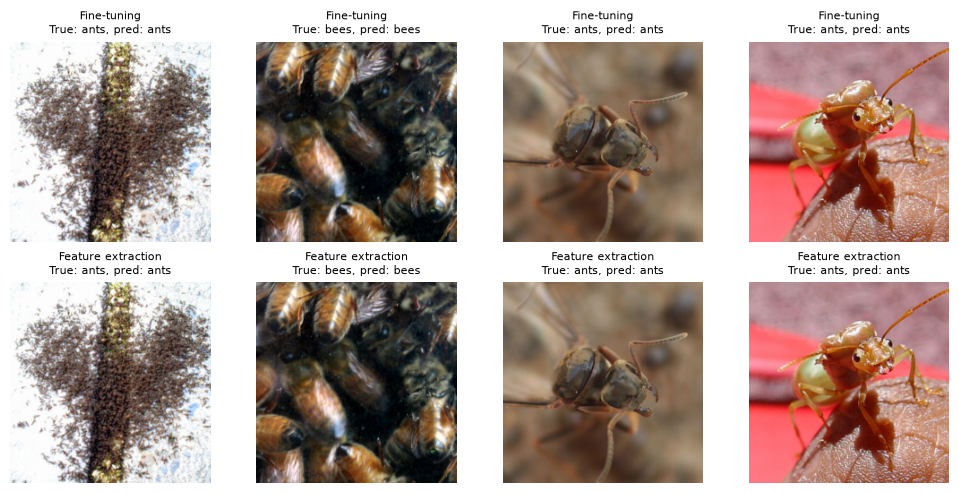

### Comparison and discussion
Fine-tuning reaches **92.81%** validation accuracy with loss
**0.1720**. Feature extraction reaches **96.08%**
with loss **0.1230**. The accuracy difference (fine-tuning minus
feature extraction) is **-3.27 percentage points**.
The corresponding training accuracies are 100.00% and
97.54%. Training images are evaluated with center crops for these figures.

Fine-tuning can adjust the pretrained visual features to this dataset, but fits many
more parameters from only 244 training images. Feature extraction
relies on the features already learned from ImageNet and trains only the classifier.
The timing table shows the computational cost of each approach on this machine;
it includes training and per-epoch evaluation, but excludes downloading weights.
The fixed backbone still needs a forward pass for every image.

There are only 153 validation images, so one additional correct prediction
changes accuracy by 0.65 percentage points. Small differences
should therefore be interpreted cautiously. One seed and one split do not establish
a general ranking, and no separate held-out test set is available here. Freezing the
backbone's batch-normalization statistics makes this a strict feature extractor;
the tutorial's training-mode implementation can update those statistics.

Saved measured results to results/metrics.json


In [9]:
print("Method              Trainable params  Train acc  Val acc  Val loss  Time (s)")
for name, result in transfer_results.items():
    h = result["history"][-1]
    print(f"{name:19s} {result['parameters']:16d} {h['train_acc']:10.2f}"
          f" {h['test_acc']:8.2f} {h['test_loss']:9.4f} {result['seconds']:9.1f}")

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
indices = [insect_val.targets.index(0), insect_val.targets.index(1)]
indices += [i for i in range(len(insect_val)) if i not in indices][:2]
for row, (name, model) in enumerate(transfer_models.items()):
    model.eval()
    for col, i in enumerate(indices):
        x, y = insect_val[i]
        with torch.no_grad():
            pred = model(x.unsqueeze(0).to(device)).argmax(1).item()
        image = (x * torch.tensor(std)[:, None, None] + torch.tensor(mean)[:, None, None])
        axes[row, col].imshow(image.permute(1, 2, 0).clamp(0, 1))
        axes[row, col].set_title(name + "\nTrue: " + insect_val.classes[y] +
                                 ", pred: " + insect_val.classes[pred], fontsize=8)
        axes[row, col].axis("off")
save_figure("transfer_predictions")

fine = transfer_results["Fine-tuning"]["history"][-1]
fixed = transfer_results["Feature extraction"]["history"][-1]
display(Markdown(f"""### Comparison and discussion
Fine-tuning reaches **{fine['test_acc']:.2f}%** validation accuracy with loss
**{fine['test_loss']:.4f}**. Feature extraction reaches **{fixed['test_acc']:.2f}%**
with loss **{fixed['test_loss']:.4f}**. The accuracy difference (fine-tuning minus
feature extraction) is **{fine['test_acc'] - fixed['test_acc']:.2f} percentage points**.
The corresponding training accuracies are {fine['train_acc']:.2f}% and
{fixed['train_acc']:.2f}%. Training images are evaluated with center crops for these figures.

Fine-tuning can adjust the pretrained visual features to this dataset, but fits many
more parameters from only {len(insect_train)} training images. Feature extraction
relies on the features already learned from ImageNet and trains only the classifier.
The timing table shows the computational cost of each approach on this machine;
it includes training and per-epoch evaluation, but excludes downloading weights.
The fixed backbone still needs a forward pass for every image.

There are only {len(insect_val)} validation images, so one additional correct prediction
changes accuracy by {100 / len(insect_val):.2f} percentage points. Small differences
should therefore be interpreted cautiously. One seed and one split do not establish
a general ranking, and no separate held-out test set is available here. Freezing the
backbone's batch-normalization statistics makes this a strict feature extractor;
the tutorial's training-mode implementation can update those statistics."""))

results = dict(seed=SEED, device=str(device), torch_version=str(torch.__version__),
               dense=dict(history=dense_history, seconds=dense_seconds),
               mnist=mnist_results, transfer=transfer_results)
Path("results/metrics.json").write_text(json.dumps(results, indent=2))
print("Saved measured results to results/metrics.json")

### Interpreting the transfer-learning curves
Fine-tuning reaches 100.00% training accuracy, but its final
validation accuracy is 92.81%, below its highest observed value
of 94.77%. This pattern is consistent with overfitting:
a better fit to the training images does not guarantee better validation accuracy.
Feature extraction ends at 96.08% validation accuracy while
updating far fewer parameters. For this run, keeping the pretrained features fixed
works better at the final epoch. This does not mean fine-tuning is generally worse;
its result depends on the learning rate, training duration and amount of data.
The reported comparison uses epoch 10 for both methods.
